In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [3]:
df=pd.read_csv(r"C:\Users\bachu\Desktop\5thsem_OJT\project1_diabetes\data\processed\muhammed_bilal_p1w2_features.csv")

In [4]:
feature_cols = ["age","pregnancies","glucose","blood_pressure",
                "skin_thickness","insulin","bmi","diabetes_pedigree",
                "bmi_category","glucose_band"]

#create a list for wanted columns
#then save independent and depend variables

x = df[feature_cols].copy()
y = df["outcome"]
x

,age,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,bmi_category,glucose_band
0,79,0,124.0,71.0,30.0,124.0,23.4,0.588,normal,prediabetic
1,37,0,153.0,85.0,24.0,42.0,33.9,0.192,obese,diabetic
2,39,0,142.0,68.0,22.0,159.0,26.9,0.777,overweight,diabetic
3,68,7,121.0,88.0,26.0,124.0,29.0,1.217,overweight,prediabetic
4,75,0,107.0,84.0,31.0,101.0,21.2,0.278,normal,prediabetic
...,...,...,...,...,...,...,...,...,...,...
945,64,2,117.0,81.0,34.0,124.0,40.3,0.641,obese,prediabetic
946,71,0,140.0,64.0,37.0,124.0,33.4,0.116,obese,diabetic
947,40,0,130.0,73.0,26.0,258.0,20.1,0.709,normal,diabetic
948,52,4,123.0,76.0,22.0,189.0,38.9,0.540,obese,prediabetic


In [5]:
x=pd.get_dummies(x,drop_first=True)
#drop_first is used for after new column add before columns removing function
#get_dummies is used for value to numerical value function
x.shape

(950, 13)

In [6]:
x_train,x_test,y_train,y_test= train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)

In [7]:
scaler = StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)#Calculates the mean and standard deviation from x train
x_test_scaled=scaler.transform(x_test)#Uses those values to standardize x_train.

In [8]:
logreg = LogisticRegression(max_iter=1000).fit(x_train_scaled,y_train)
knn = KNeighborsClassifier(n_neighbors=25).fit(x_train_scaled, y_train)
decision_tree = DecisionTreeClassifier(max_depth=3,random_state=42).fit(x_train, y_train)

In [9]:
print("Logistic Regression", accuracy_score(y_test, logreg.predict(x_test_scaled)))

print("Decision Tree", accuracy_score(y_test, decision_tree.predict(x_test)))

print("KNN", accuracy_score(y_test, knn.predict(x_test_scaled)))

Logistic Regression 0.7526315789473684
Decision Tree 0.7210526315789474
KNN 0.7473684210526316


In [10]:
print("\nTest set:", len(y_test), "patients |",
      int(np.sum(y_test)), "of them diabetic")


Test set: 190 patients | 55 of them diabetic


In [11]:
models = [("Logistic Regression",logreg,x_test_scaled),
          ("decision_tree(d=3)",decision_tree, x_test),
          ("knn(k=25)",      knn, x_test_scaled)]

In [12]:
for name, m, Xt in models:
    print(f"{name:22s} accuracy = {accuracy_score(y_test, m.predict(Xt)):.4f}")

print("\nTest set:", len(y_test), "patients |", int(np.sum(y_test)), "of them diabetic")

Logistic Regression    accuracy = 0.7526
decision_tree(d=3)     accuracy = 0.7211
knn(k=25)              accuracy = 0.7474

Test set: 190 patients | 55 of them diabetic



buiI a contruction metrix for every modeI

In [13]:
rows = []
for name,m,Xt in models:
    cm = confusion_matrix(y_test,m.predict(Xt))
    tn, fp, fn, tp = cm.ravel()
    rows.append({"models": name, "correct_negative": int(tn),"False_alarms":int(fp),
                 "missed_patients":int(fn),"found_patients":int(tp),
                 "accuracy":accuracy_score(y_test,m.predict(Xt))})
    

In [14]:
metrices = pd.DataFrame(rows)
metrices

,models,correct_negative,False_alarms,missed_patients,found_patients,accuracy
0,Logistic Regression,127,8,39,16,0.752632
1,decision_tree(d=3),121,14,39,16,0.721053
2,knn(k=25),132,3,45,10,0.747368


### Decision Tree (max_depth = 3)

The Decision Tree achieved an accuracy of **72.11%** on 190 test patients.

- **121** patients were correctly identified as non-diabetic.
- **14** patients were incorrectly identified as diabetic.
- **39** diabetic patients were missed by the model.
- **16** diabetic patients were correctly detected.

Overall, the model made **137 correct predictions out of 190 patients**.

### Logistic Regression — Error Analysis

- **False Positive (False Alarm):** 8
- **False Negative (Missed Patient):** 39

The model has **31 more False Negatives than False Positives**.

False Negatives are much higher and therefore **dominate the errors**.
The model misses more diabetic patients than it incorrectly identifies non-diabetic patients as diabetic.

score the modeI that Iast says yes

In [15]:
from  sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train,y_train)
y_pred=dummy.predict(x_test)
confusion_matrix(y_test,y_pred)

array([[135,   0],
       [ 55,   0]])

In [16]:
accuracy_score(y_test,y_pred)

0.7105263157894737

In [17]:
y_test.value_counts(normalize=True)

outcome
0    0.710526
1    0.289474
Name: proportion, dtype: float64

## Recall and precision

Recall

Recall tells us how many actual positive cases the model correctly found.

Formula:
Recall = TP / (TP + FN)

Simple: How many actual positive cases did the model find?

In [18]:
cm = confusion_matrix(y_test,logreg.predict(x_test_scaled))
tn,fp,fn,tp = cm.ravel()
print("recaII : tp / tp+fn",tp/(tp+fn))

from sklearn.metrics import recall_score
recall= recall_score(y_test,logreg.predict(x_test_scaled))
recall

recaII : tp / tp+fn 0.2909090909090909


0.2909090909090909

In [19]:
print("Iogistic regression  Recall =",recall_score(y_test,logreg.predict(x_test_scaled)))
print("DecisionTreeClassifier  Recall =",recall_score(y_test,decision_tree.predict(x_test)))
print("KNeighborsClassifier  Recall =",recall_score(y_test,knn.predict(x_test_scaled)))


Iogistic regression  Recall = 0.2909090909090909
DecisionTreeClassifier  Recall = 0.2909090909090909
KNeighborsClassifier  Recall = 0.18181818181818182


Precision

Precision tells us how many predicted positive cases were actually positive.

Formula:
Precision = TP / (TP + FP)

Simple: How accurate are the positive predictions?

In [20]:
print("precesion : tp / tp+fp",tp/(tp+fp))

precesion : tp / tp+fp 0.6666666666666666


In [21]:
from sklearn.metrics import precision_score

precision_score(y_test,logreg.predict(x_test_scaled))
print("DecisionTreeClassifier  precision =",precision_score(y_test,decision_tree.predict(x_test)))
print("KNeighborsClassifier  precision =",precision_score(y_test,knn.predict(x_test_scaled)))
print("LogisticRegression  precision=",precision_score(y_test,logreg.predict(x_test_scaled)))

DecisionTreeClassifier  precision = 0.5333333333333333
KNeighborsClassifier  precision = 0.7692307692307693
LogisticRegression  precision= 0.6666666666666666


sort by recaII


In [22]:
rows = []
for name,m,xt in models:
    y_pred = m.predict(xt)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    rows.append({
        "model": name,
        "accuracy": round(accuracy_score(y_test,y_pred),4),
        "precision":round(precision_score(y_test,y_pred),4),
        "recall": round(recall_score(y_test,y_pred),4),
        "found":int(tp),"missed":int(fn),"false_alarm": int(fp)
    })
result = pd.DataFrame(rows)


print(result.sort_values(by="precision", ascending=False).to_string())

print(result.sort_values(by="recall", ascending=False).to_string())


                 model  accuracy  precision  recall  found  missed  false_alarm
2            knn(k=25)    0.7474     0.7692  0.1818     10      45            3
0  Logistic Regression    0.7526     0.6667  0.2909     16      39            8
1   decision_tree(d=3)    0.7211     0.5333  0.2909     16      39           14
                 model  accuracy  precision  recall  found  missed  false_alarm
0  Logistic Regression    0.7526     0.6667  0.2909     16      39            8
1   decision_tree(d=3)    0.7211     0.5333  0.2909     16      39           14
2            knn(k=25)    0.7474     0.7692  0.1818     10      45            3


In [23]:
probs = logreg.predict_proba(x_test_scaled)[:, 1]
preds = logreg.predict(x_test_scaled)

pd.DataFrame({"probability": probs[: 10].round(3),
              "prediction" : preds[:10],
              "actuall"    : np.asarray(y_test)[:10]})

,probability,prediction,actuall
0,0.289,0,0
1,0.031,0,0
2,0.182,0,0
3,0.182,0,0
4,0.177,0,1
5,0.161,0,0
6,0.419,0,0
7,0.473,0,1
8,0.286,0,0
9,0.121,0,0


In [24]:
sweep = []

for t in [0.5,0.45,0.4,0.35,0.3,0.25,0.2,0.15]:
    pred_t = (probs >=t).astype(int)
    cm = confusion_matrix(y_test, pred_t)
    tn, fp, fn, tp = cm.ravel()

    sweep.append({
        "threshold": t,
        "accuracy": round(accuracy_score(y_test, pred_t), 4),
        "precision": round(precision_score(y_test, pred_t), 4),
        "recall": round(recall_score(y_test, pred_t), 4),
        "found": int(tp),
        "missed": int(fn),
        "false_alarms": int(fp)
    })
pd.DataFrame(sweep)
    
    

,threshold,accuracy,precision,recall,found,missed,false_alarms
0,0.50,0.7526,0.6667,0.2909,16,39,8
1,0.45,0.7316,0.5556,0.3636,20,35,16
2,0.40,0.7105,0.5000,0.4364,24,31,24
3,0.35,0.7158,0.5082,0.5636,31,24,30
4,0.30,0.6947,0.4789,0.6182,34,21,37
5,0.25,0.6158,0.4043,0.6909,38,17,56
6,0.20,0.5789,0.3874,0.7818,43,12,68
7,0.15,0.5316,0.3692,0.8727,48,7,82


## F1 Score

**F1 Score** is the balance between **precision and recall**. It is useful when we want both precision and recall to be important.

**Formula:** `F1 Score = 2 × (Precision × Recall) / (Precision + Recall)`

Precision: Out of all patients the model predicted as diabetic, how many were actually diabetic?

Recall: Out of all patients who actually had diabetes, how many did the model correctly find?

### F1 Score — Full Equation

The F1 Score is the **harmonic mean of Precision and Recall**.

**Step 1 — Precision:**

$$
Precision = \frac{TP}{TP + FP}
$$

**Step 2 — Recall:**

$$
Recall = \frac{TP}{TP + FN}
$$

**Step 3 — F1 Score:**

$$
F1 = \frac{2 \times Precision \times Recall}{Precision + Recall}
$$

Substituting the full formulas:

$$
F1 =
\frac{2 \times
\left(\frac{TP}{TP+FP}\right)
\times
\left(\frac{TP}{TP+FN}\right)}
{\left(\frac{TP}{TP+FP}\right)
+
\left(\frac{TP}{TP+FN}\right)}
$$

This can be simplified to:

$$
\boxed{F1 = \frac{2TP}{2TP + FP + FN}}
$$

Where:

* **TP** = True Positive
* **FP** = False Positive
* **FN** = False Negative

**F1 Score ranges from 0 to 1**, where a higher value means precision and recall are both higher.

Available next action: Create a downloadable DOCX file here in this chat containing the editable prose above


In [25]:
from sklearn.metrics import f1_score
print(f"f1_score={f1_score(y_test,logreg.predict(x_test_scaled)):.4f}")

f1_score=0.4051


In [26]:
print(f"f1_score_logistic regression={f1_score(y_test,logreg.predict(x_test_scaled)):.4f}"),
print(f"f1_score_decisiontree={f1_score(y_test,decision_tree.predict(x_test)):.4f}"),
print(f"f1_score_KNN={f1_score(y_test,knn.predict(x_test_scaled)):.4f}")

f1_score_logistic regression=0.4051
f1_score_decisiontree=0.3765
f1_score_KNN=0.2941


In [27]:
from sklearn.metrics import f1_score, classification_report
f1_score(y_test,y_pred)
print(classification_report(y_test,y_pred,digits=4))

              precision    recall  f1-score   support

           0     0.7458    0.9778    0.8462       135
           1     0.7692    0.1818    0.2941        55

    accuracy                         0.7474       190
   macro avg     0.7575    0.5798    0.5701       190
weighted avg     0.7526    0.7474    0.6864       190



#DECISION IN ONE SENTENCE

we will judge this model on how many patience with diabetes it finds,because for this clinic sending a diabetic patient home untested is a worse outcome than calling a healthy patient back for a test they did not need

#ROC CURVE PLOTS

ROC curve is a graph that shows the performance of a classification model at different thresholds using True Positive Rate and False Positive Rate.”

Text(0.5, 1.0, 'ROC/u2014 logistic regression baseline')

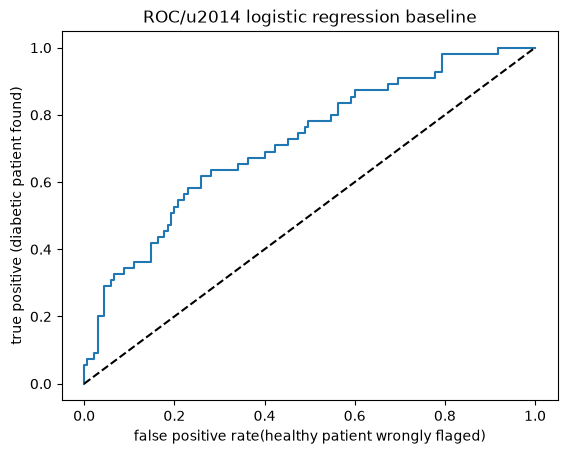

In [28]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

probs = logreg.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.xlabel('false positive rate(healthy patient wrongly flaged)')
plt.ylabel('true positive (diabetic patient found)')
plt.title('ROC/u2014 logistic regression baseline')

threshold 0.50 -> fpr 0.059  tpr (recall) 0.291
threshold 0.30 -> fpr 0.281  tpr (recall) 0.618


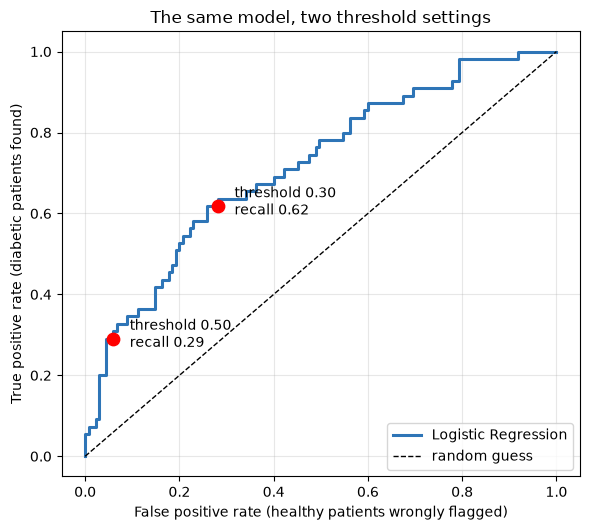

In [31]:
i_50 = int(np.argmin(np.abs(thresholds - 0.50)))
i_30 = int(np.argmin(np.abs(thresholds - 0.30)))

print(f"threshold 0.50 -> fpr {fpr[i_50]:.3f}  tpr (recall) {tpr[i_50]:.3f}")
print(f"threshold 0.30 -> fpr {fpr[i_30]:.3f}  tpr (recall) {tpr[i_30]:.3f}")

plt.figure(figsize=(6, 5.4))

plt.plot(
    fpr, tpr,
    lw=2.2,
    color="#2E75B7",
    label="Logistic Regression"
)

plt.plot(
    [0, 1], [0, 1],
    "k--",
    lw=1,
    label="random guess"
)

plt.scatter(
    fpr[[i_50, i_30]],
    tpr[[i_50, i_30]],
    s=80,
    zorder=5,
    color="red"
)
i_50 = int(np.argmin(np.abs(thresholds - 0.50)))
i_30 = int(np.argmin(np.abs(thresholds - 0.30)))
plt.annotate(f"threshold 0.50\nrecall {tpr[i_50]:.2f}",(fpr[i_50], tpr[i_50]),textcoords="offset points",xytext=(12, -6),
fontsize=10)
plt.annotate(f"threshold 0.30\nrecall {tpr[i_30]:.2f}",(fpr[i_30], tpr[i_30]),textcoords="offset points",xytext=(12, -6),
fontsize=10)

plt.xlabel("False positive rate (healthy patients wrongly flagged)")
plt.ylabel("True positive rate (diabetic patients found)")
plt.title("The same model, two threshold settings")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PLOT ALL THREE CURVES TOGETHER

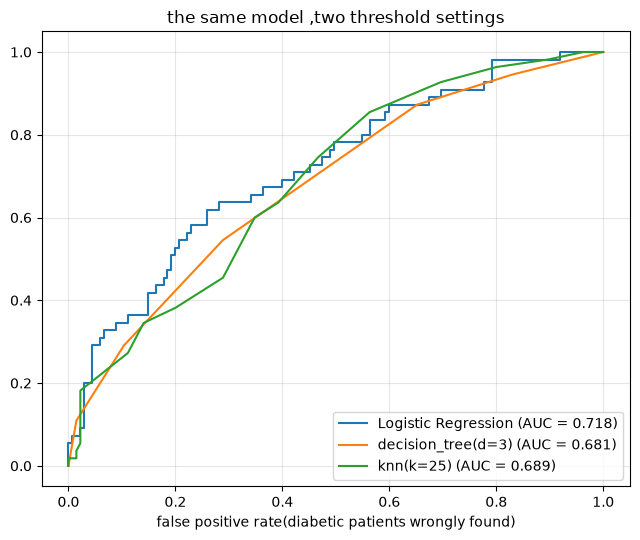

In [32]:
from sklearn.metrics import auc
plt.figure(figsize=(6.5,5.5))
for name,m,Xt in models:
    p= m.predict_proba(Xt)[:,1]
    f,t,thresholds = roc_curve(y_test,p)
    auc_score= auc(f,t)
    plt.plot(f,t,label=f"{name} (AUC = {auc_score:.3f})")


plt.xlabel("true positive rate(diabetic patients found)")
plt.xlabel("false positive rate(diabetic patients wrongly found)")
plt.title("the same model ,two threshold settings")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

LEARN WHAT AUC MEASURES

AUC (Area Under the Curve) is a measure that shows how well a classification model can distinguish between two classes.

explain what the area under the curve represents and what values of 0.5 and 1.0 would each mean
The area under the ROC curve (AUC) represents how well a classification model can separate positive and negative classes.

AUC = 0.5: The model is performing like random guessing. It cannot properly distinguish between the two classes.
AUC = 1.0: The model has perfect classification ability. It can completely distinguish between the positive and negative classes.